In [1]:
%matplotlib widget

import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
from typing import Literal

from helpers.plotting import plot_performance, plot_gradients, plot_weight_matrices, InteractiveSpikePlot

In [2]:
work_dir = Path.cwd()

n_trials = 5

def load_recording(data_name: str, key: str, skip_is: list[int] = []) -> np.ndarray:
    data = []
    for i in range(1, n_trials + 1):
        if i not in skip_is:
            with np.load(work_dir / f"seed_{i}" / "data_net" / f"{data_name}.npz") as d:
                data.append(d[key])
    return np.array(data)

def get_data(data_name: str, skip_is: list[int] = []) -> dict[np.ndarray]:
    with np.load(work_dir / f"seed_1" / "data_net" / f"{data_name}.npz") as d:
        keys = list(d.keys())
    return {key: load_recording(data_name, key, skip_is) for key in keys}

def get_data_seed(data_name: str, seed: int) -> dict[np.ndarray]:
    with np.load(work_dir / f"seed_{seed}" / "data_net" / f"{data_name}.npz") as d:
        return {key: d[key] for key in list(d.keys())}

def filter_seeds(data: np.ndarray, seeds: list[int]) -> np.ndarray:
    return np.take(data, seeds, axis=0)

def unpack_bits(data: dict[np.ndarray], key: str, suffix: str = "-n_cols") -> np.ndarray:
    unpack_key = key + suffix
    if unpack_key in data.keys():
        return np.unpackbits(data[key], axis=-1, count=int(data[unpack_key])).astype(bool)
    return data[key]

def get_neurons(seed: int) -> dict[np.ndarray]:
    return np.load(work_dir / f"seed_{seed}" / f"neurons.npy").squeeze()

neuron_map = {
    "Excitatory": 1,
    "PV": 2,
    "SOM": 3,
}

def get_neuron_range(neurons: np.ndarray, neuron_type: Literal["Excitatory", "PV", "SOM"]) -> tuple[int, int]:
    key = neuron_map[neuron_type]
    return (
        np.min(np.where(neurons == key)),
        np.max(np.where(neurons == key))
    )

def get_neuron_ranges(neurons: np.ndarray) -> dict[str, tuple[int, int]]:
    return {k: get_neuron_range(neurons, k) for k in neuron_map.keys()}

def get_weight_masks(seed: int) -> dict[np.ndarray]:
    with np.load(work_dir / f"seed_{seed}" / f"net_weights_masks.npz") as d:
        return {key: d[key] for key in list(d.keys())}

In [3]:
skip_is = []

[[False False False False False False False False False False False False
  False False False False False False False False False False False False
  False False False False False False False False False False False False
  False False False False False False False False False False False False
  False False]
 [False False False False False False False False False False False False
  False False False False False False False False False False False False
  False False False False False False False False False False False False
  False False False False False False False False False False False False
  False False]
 [False False False False False False False False False False False False
  False False False False False False False False False False False False
  False False False False False False False False False False False False
  False False False False False False False False False False False False
  False False]
 [False False False False False False False False False False False

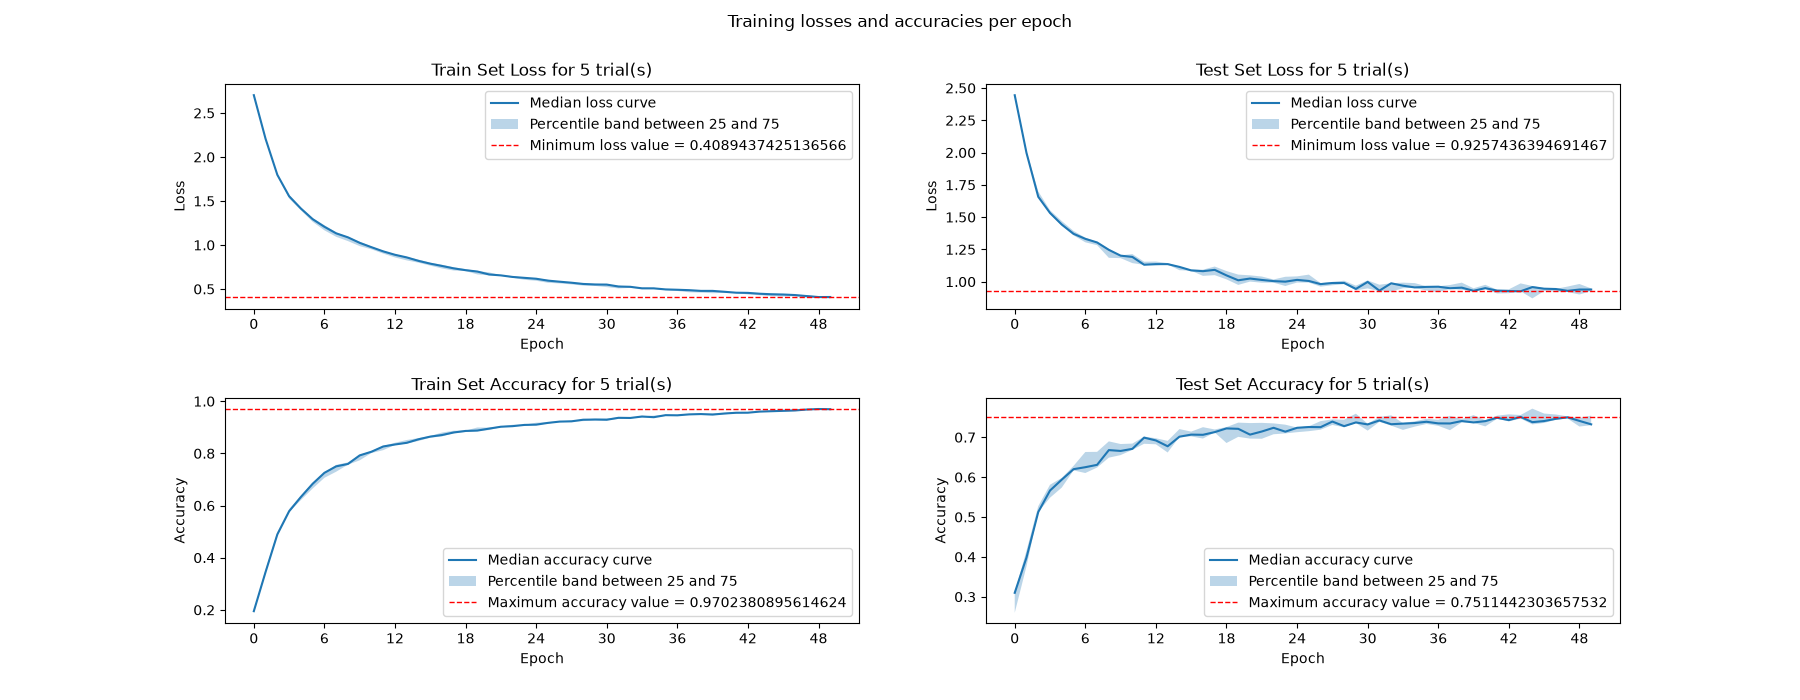

In [4]:
plot_seeds = [0, 1, 2, 3, 4]
perf_data = get_data("performance", skip_is)
print(np.isnan(perf_data["loss_train"]))
plot_performance(
    loss_train=filter_seeds(perf_data["loss_train"], plot_seeds),
    acc_train=filter_seeds(perf_data["acc_train"], plot_seeds),
    loss_test=filter_seeds(perf_data["loss_test"], plot_seeds),
    acc_test=filter_seeds(perf_data["acc_test"], plot_seeds),
)

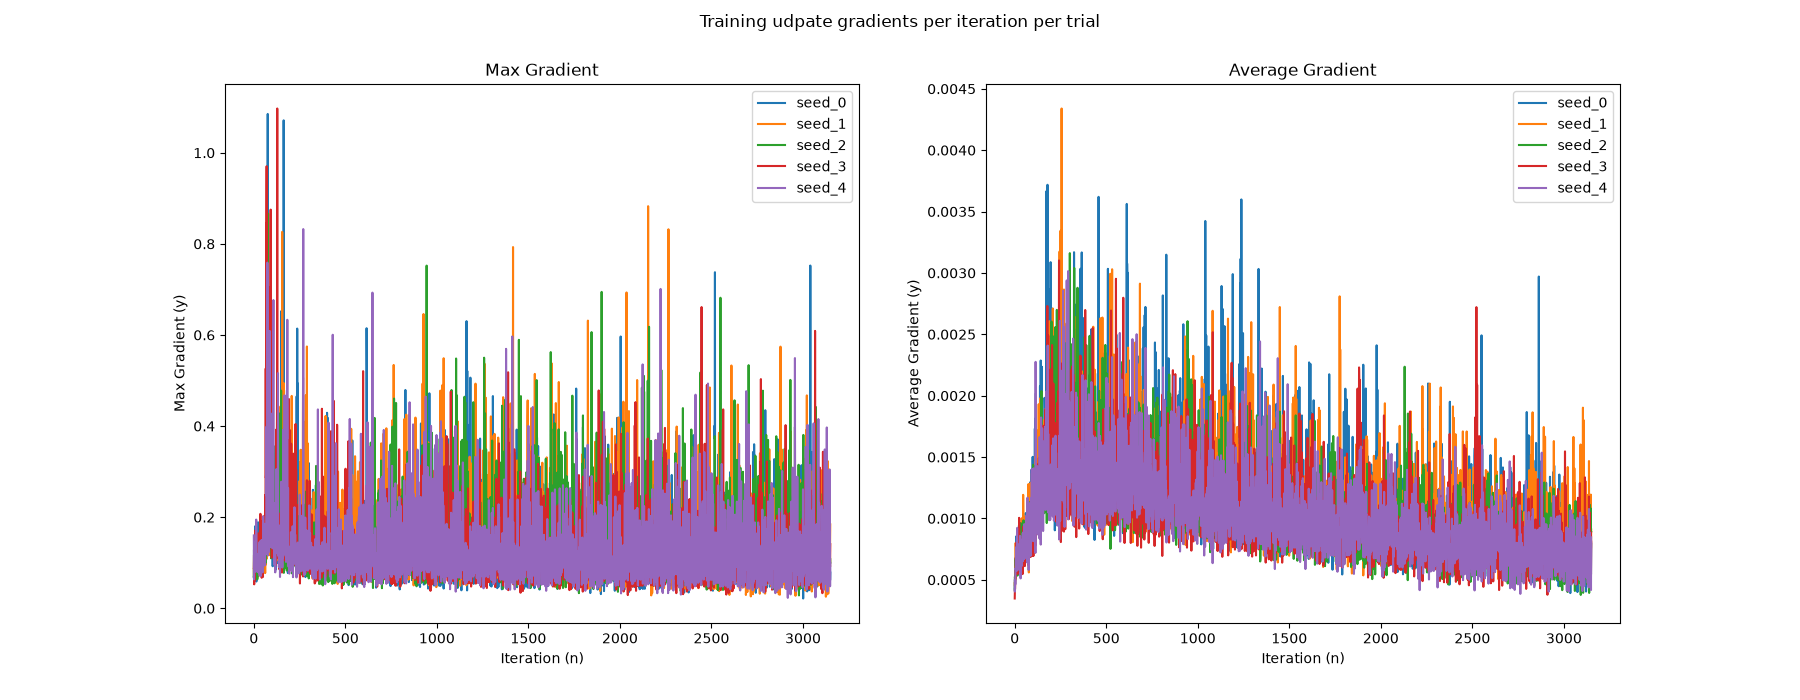

In [5]:
grad_data = get_data("gradients", skip_is)
max_grad_rec = filter_seeds(grad_data["max_grad"], plot_seeds)
avg_grad_rec = filter_seeds(grad_data["avg_grad"], plot_seeds)
plot_gradients(max_grad_rec, avg_grad_rec)

In [4]:
neurons = get_neurons(seed=1)
neuron_ranges = get_neuron_ranges(neurons)

In [ ]:
weights = get_data_seed("weights", seed=0)
print(weights.keys())
weight_masks = get_weight_masks(seed=0)
print(weight_masks.keys())
weights["weights_recurrent_0"] = weights["weights_recurrent_0"] * weight_masks["recurrent_mask_0"].T        # con_matrix is transposed in linears.py

add_ranges_to_which = [1]
for i, (key, data) in enumerate(weights.items()):
    if i in add_ranges_to_which:
        plot_weight_matrices(data, neuron_ranges, name=key)
    else:
        plot_weight_matrices(data, None, name=key)

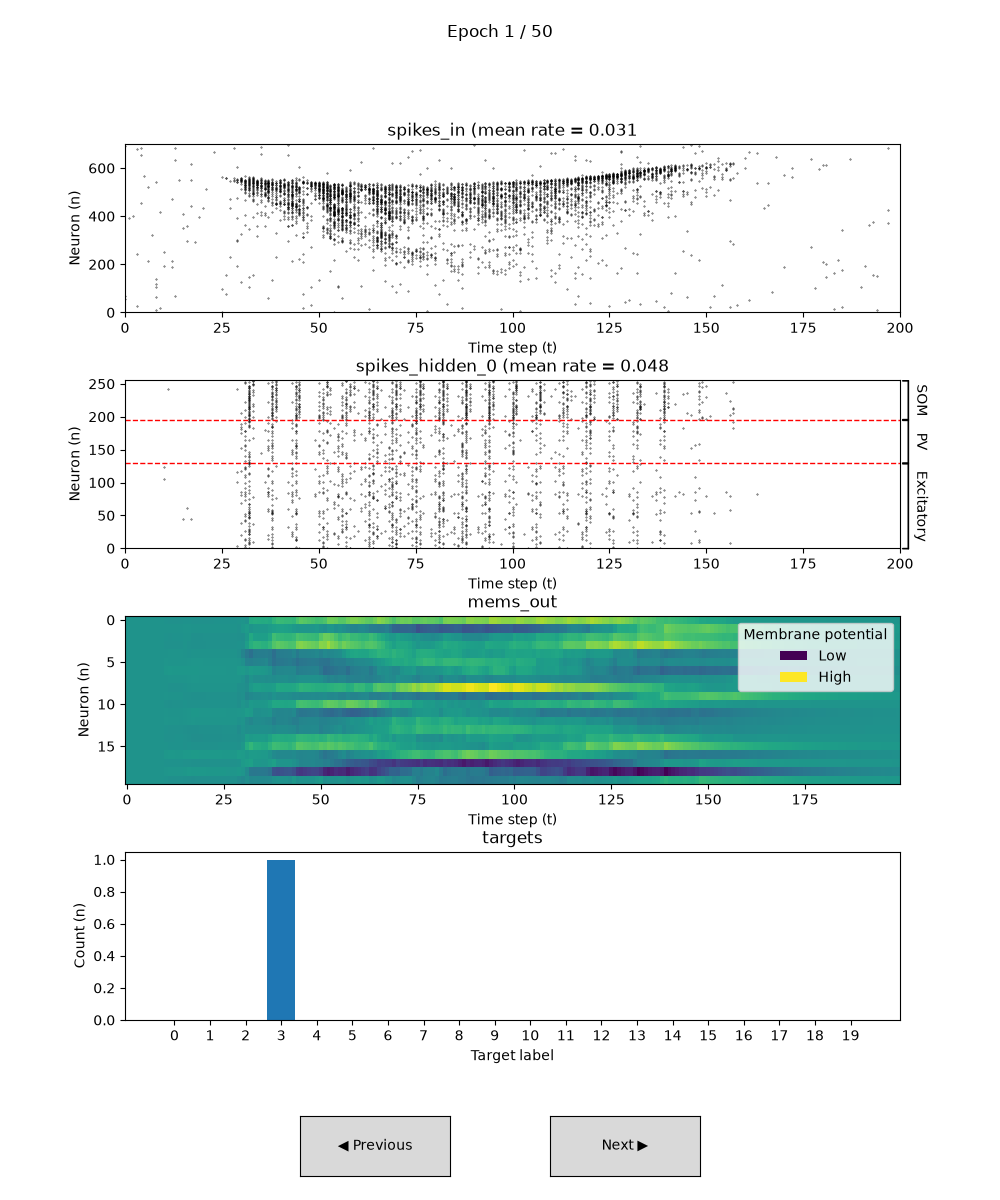

In [5]:
data = get_data_seed("spikes", seed=1)
layer_spikes = {
    k: unpack_bits(data, k)
    for k in ["spikes_in", "spikes_hidden_0", "mems_out", "targets"]
    if not k.endswith(("-lengths", "-n_cols"))
}

isp = InteractiveSpikePlot(layer_spikes, range(20), neuron_ranges)
# isp.draw()
# isp.save_as_pdf()
isp.save_as_pptx(path="spikes_plot_yes_daleslaw_yes_connectivity.pptx")